In [144]:
import pandas as pd 
import numpy as np
from matplotlib import pyplot as plt
# import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
""" 
Load and clean the prices
Load food-prices-kenya.csv, turn the date column into real dates, add year and month columns, and fill the missing county and region for the market that has none.
How many rows, markets and commodities does the file have, and what are the first and last dates?
"""

' \nLoad and clean the prices\nLoad food-prices-kenya.csv, turn the date column into real dates, add year and month columns, and fill the missing county and region for the market that has none.\nHow many rows, markets and commodities does the file have, and what are the first and last dates?\nWhich market has no county, and how many rows does that affect?\n'

#### Load the data

In [60]:
df = pd.read_csv(r"C:\Users\rose odiwuor\OneDrive\Documents\Lux Projects\food_prices_kenya\data\food_prices_kenya.csv")

df.columns

Index(['date', 'region', 'county', 'market', 'commodity', 'price_type', 'unit',
       'price_kes', 'price_usd'],
      dtype='str')

In [61]:
df.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94


In [62]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2742 entries, 0 to 2741
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   date        2742 non-null   str    
 1   region      2683 non-null   str    
 2   county      2683 non-null   str    
 3   market      2742 non-null   str    
 4   commodity   2742 non-null   str    
 5   price_type  2742 non-null   str    
 6   unit        2742 non-null   str    
 7   price_kes   2742 non-null   float64
 8   price_usd   2742 non-null   float64
dtypes: float64(2), str(7)
memory usage: 192.9 KB


In [63]:
df.describe()

,price_kes,price_usd
count,2742.000000,2742.000000
mean,2239.335748,25.127372
std,2576.989414,28.185014
min,6.000000,0.074000
25%,55.000000,0.600000
50%,1313.335000,18.170000
75%,3733.000000,45.082500
max,10350.000000,115.150000


In [64]:
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd
1086,2015-05-15,Rift Valley,Baringo,Marigat,Maize,Retail,KG,45.00,0.47
1293,2019-06-15,Eastern,Marsabit,Marsabit,Maize,Retail,KG,47.00,0.46
2370,2007-07-15,Coast,Mombasa,Mombasa,Maize,Wholesale,90 KG,1183.91,17.74
387,2018-08-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,60.00,0.60
1849,2010-07-15,Nairobi,Nairobi,Nairobi,Beans,Wholesale,90 KG,4664.00,57.30


In [65]:
# check for duplicates
df.duplicated().sum()

np.int64(0)

#### clean the data

In [66]:
#turn the date column into real dates
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["date"].sample(10, random_state=42)

859    2015-04-15
1521   2010-08-15
1322   2007-11-15
1352   2010-05-15
2031   2006-11-15
2518   2006-03-15
2201   2007-02-15
798    2010-02-15
1110   2017-06-15
1900   2014-10-15
Name: date, dtype: datetime64[us]

In [67]:
# extract and add year and month columns
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month

In [68]:
df.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month
1519,2010-06-15,Nyanza,Kisumu,Kisumu,Beans,Wholesale,90 KG,4252.0,52.79,2010,6
618,2009-02-15,Eastern,Kitui,Kitui,Maize,Retail,KG,35.0,0.44,2009,2
349,2015-05-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,60.0,0.63,2015,5
677,2014-01-15,Eastern,Kitui,Kitui,Maize,Retail,KG,37.0,0.43,2014,1
442,2018-04-15,NaN,NaN,Hola,Maize,Retail,KG,50.0,0.50,2018,4


In [ ]:
# Which market has no county, and how many rows does that affect? Hola -> 59 rows
nulls = (
    df[df["county"].isna()]          # keep only rows where county is missing
    .groupby("market")
    .size()
    .sort_values(ascending=False)
)
print(nulls)

market
Hola    59
dtype: int64


In [70]:
# Fill the missing county and region for Hola market
# Hola is located in Tana River county within the Coast region
df.loc[df['market'] == 'Hola', 'county'] = df.loc[df['market'] == 'Hola', 'county'].fillna('Tana River')
df.loc[df['market'] == 'Hola', 'region'] = df.loc[df['market'] == 'Hola', 'region'].fillna('Coast')

In [ ]:
# How many rows, markets and commodities does the file have, and what are the first and last dates?
print(df.shape)
# 2742 rows

(2742, 11)

In [109]:
unique_markets = df['market'].nunique()
print(f"Number of markets: {unique_markets}")

Number of markets: 14


In [110]:
unique_commodities = df['commodity'].nunique()
print(f"Number of commodities: {unique_commodities}")

Number of commodities: 2


In [ ]:
# what are the first and last dates?
highest_date = df['date'].max()
lowest_date = df['date'].min()

print(f"First date: {lowest_date}")         
print(f"Last date: {highest_date}")         

First date: 2006-01-15 00:00:00
Last date: 2019-12-15 00:00:00


In [ ]:
""" Compare like with like
Split the data into wholesale (per 90 KG bag) and retail (per KG) prices and never average them together. 
Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
- Which units appear for wholesale maize and for retail maize?
- On average, how does the retail price per KG of maize compare with the wholesale price per KG?
"""


In [ ]:
# Which units appear for wholesale maize and for retail maize?
df[df["commodity"] == "Maize"].groupby(["price_type", "unit"]).size()

# wholesale maize is always quoted per 90 KG bag, retail maize always per KG.

price_type  unit 
Retail      KG       955
Wholesale   90 KG    721
dtype: int64

In [ ]:
# Add a price_per_kg column so you can compare what a trader pays per KG with what a household pays per KG.
df["price_per_kg"] = np.where(df["unit"] == "90 KG", df["price_kes"] / 90, df["price_kes"])

In [115]:
# Split the data into wholesale (per 90 KG bag) 
df_wholesale = df[(df["price_type"] == "Wholesale") & (df["unit"] == "90 KG")].copy()
df_wholesale.sample(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
2638,2016-03-15,Nairobi,Nairobi,Nairobi,Maize,Wholesale,90 KG,2640.0,26.04,2016,3,29.333333
1668,2009-02-15,Coast,Mombasa,Mombasa,Beans,Wholesale,90 KG,4513.0,56.77,2009,2,50.144444
1426,2016-08-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,7650.0,75.46,2016,8,85.000000
2047,2008-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1175.0,18.04,2008,3,13.055556
1311,2006-12-15,Rift Valley,Uasin Gishu,Eldoret,Beans,Wholesale,90 KG,2600.0,37.38,2006,12,28.888889


In [ ]:
# split the dataset into a retail (per KG)
df_retail = df[(df["price_type"] == "Retail") & (df["unit"] == "KG")].copy()
df_retail.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
0,2015-01-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,87.3,0.96,2015,1,87.3
1,2015-02-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,81.9,0.90,2015,2,81.9
2,2015-03-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,82.2,0.89,2015,3,82.2
3,2015-04-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,85.0,0.91,2015,4,85.0
4,2015-05-15,Rift Valley,Kajiado,Kajiado,Beans,Retail,KG,90.0,0.94,2015,5,90.0


In [116]:
# how does the retail price per KG of maize compare with the wholesale price per KG?
wholesale_kg = df_wholesale.loc[df_wholesale["commodity"] == "Maize", "price_per_kg"].mean()
retail_kg = df_retail.loc[df_retail["commodity"] == "Maize", "price_per_kg"].mean()
print(f"Wholesale maize: KES {wholesale_kg:.2f} per kg")
print(f"Retail maize:    KES {retail_kg:.2f} per kg")
print(f"Retail is KES {retail_kg - wholesale_kg:.2f} per kg more, about {(retail_kg / wholesale_kg - 1) * 100:.0f}% higher")


Wholesale maize: KES 28.54 per kg
Retail maize:    KES 47.92 per kg
Retail is KES 19.38 per kg more, about 68% higher


In [ ]:
"""
Maize prices over the years
Calculate the average wholesale maize price per bag for each year and the year-on-year change. 
Plot the yearly average as a line chart with the price in KES on the y-axis.

Which year had the highest average wholesale maize price?
Which year saw the biggest rise, and which saw the biggest fall, compared with the year before?
"""

'\nMaize prices over the years\nCalculate the average wholesale maize price per bag for each year and the year-on-year change. \nPlot the yearly average as a line chart with the price in KES on the y-axis.\n\nWhich year had the highest average wholesale maize price?\nWhich year saw the biggest rise, and which saw the biggest fall, compared with the year before?\n'

In [88]:
df_maize = df[(df["commodity"] == "Maize") & (df["price_type"] == "Wholesale")].copy()
df_maize.head(5)

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
2021,2006-01-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1192.00,16.58,2006,1,13.244444
2022,2006-02-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1304.00,18.19,2006,2,14.488889
2023,2006-03-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1162.22,16.06,2006,3,12.913556
2024,2006-04-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1277.00,17.96,2006,4,14.188889
2025,2006-05-15,Rift Valley,Uasin Gishu,Eldoret,Maize,Wholesale,90 KG,1445.26,20.16,2006,5,16.058444


In [117]:
# average wholesale maize price per bag for each year
yearly_avg = df_maize.groupby("year")["price_kes"].mean().reset_index().round(2)
yearly_avg

,year,price_kes
0,2006,1395.04
1,2007,1207.45
2,2008,1906.32
3,2009,2513.27
4,2010,1773.95
5,2011,3020.22
6,2012,3173.78
7,2013,2962.46
8,2014,2993.72
9,2015,2690.15


In [118]:
# rename price_kes to avg_price_kes
yearly_avg.columns = ["year", "avg_price_kes"]
yearly_avg.columns

Index(['year', 'avg_price_kes'], dtype='str')

In [124]:
# year-on-year change of the average prices
yearly_avg["yoy_change_kes"] = yearly_avg["avg_price_kes"].diff()
yearly_avg

,year,avg_price_kes,yoy_change_kes
0,2006,1395.04,NaN
1,2007,1207.45,-187.59
2,2008,1906.32,698.87
3,2009,2513.27,606.95
4,2010,1773.95,-739.32
5,2011,3020.22,1246.27
6,2012,3173.78,153.56
7,2013,2962.46,-211.32
8,2014,2993.72,31.26
9,2015,2690.15,-303.57


In [125]:
yearly_avg.max()

year              2019.00
avg_price_kes     3743.68
yoy_change_kes    1246.27
dtype: float64

In [126]:
yearly_avg.min()

year              2006.00
avg_price_kes     1207.45
yoy_change_kes   -1335.29
dtype: float64

In [129]:
# Which year had the highest average wholesale maize price?
# Which year saw the biggest rise, and which saw the biggest fall, compared with the year before?

highest_year = yearly_avg.loc[yearly_avg["avg_price_kes"].idxmax(), "year"]  
biggest_rise = yearly_avg.loc[yearly_avg["yoy_change_kes"].idxmax(), "year"]  
biggest_fall = yearly_avg.loc[yearly_avg["yoy_change_kes"].idxmin(), "year"]  
print(f"Highest average year: {highest_year}")
print(f"Biggest rise: {biggest_rise}, biggest fall: {biggest_fall}")

Highest average year: 2017
Biggest rise: 2011, biggest fall: 2018


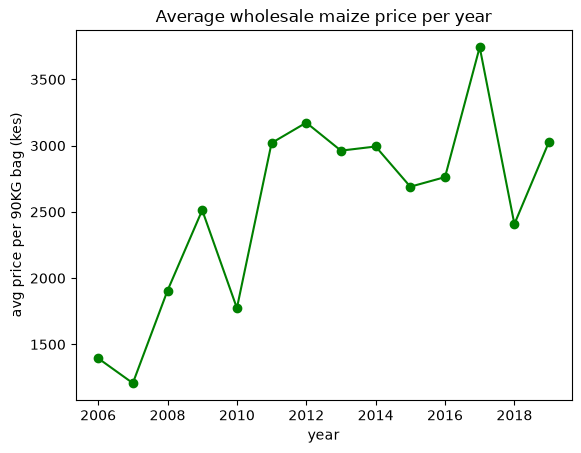

In [131]:
# Plot the yearly average as a line chart with the price in KES on the y-axis.
# x axis -> year
# y axis -> avg_price_kes

plt.plot(yearly_avg["year"], yearly_avg["avg_price_kes"], color="green", marker="o")
plt.title("Average wholesale maize price per year")
plt.xlabel("year")
plt.ylabel("avg price per 90KG bag (kes)")
plt.show()

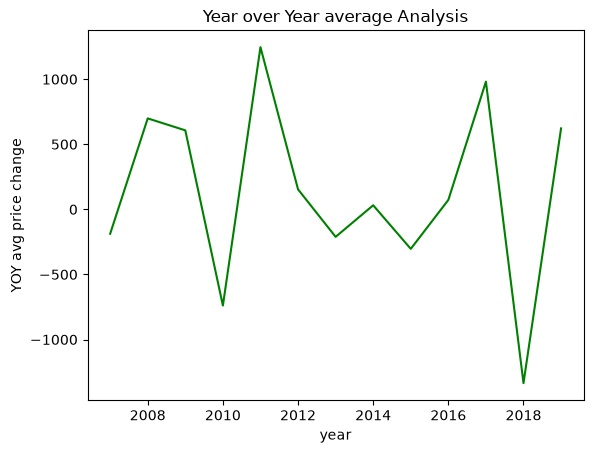

In [132]:
plt.plot(yearly_avg["year"], yearly_avg["yoy_change_kes"], color="green")
plt.title("Year over Year average Analysis")
plt.xlabel("year")
plt.ylabel("YOY avg price change")
plt.show()

In [ ]:
""" 
Sell at harvest or hold?
Average wholesale maize prices by month to find the seasonal pattern. Then compare each market's January and June price, year by year, 
to see how often storing maize for five months paid off.

In which month is wholesale maize cheapest on average, and in which is it dearest?
# January, KES 2330
# June, KES 2839

In what share of market-years was the June price higher than the January price, and what was the median gain?

What costs and risks of storing maize does this calculation leave out
"""

" \nSell at harvest or hold?\nAverage wholesale maize prices by month to find the seasonal pattern. Then compare each market's January and June price, year by year, \nto see how often storing maize for five months paid off.\n\nIn which month is wholesale maize cheapest on average, and in which is it dearest?\n# January, KES 2330\n# June, KES 2839\n\nIn what share of market-years was the June price higher than the January price, and what was the median gain?\n\nWhat costs and risks of storing maize does this calculation leave out\n"

In [139]:
# Average wholesale maize prices by month to find the seasonal pattern
monthly_avg = df_maize.groupby("month")["price_kes"].mean().reset_index().round()
monthly_avg

,month,price_kes
0,1,2330.0
1,2,2405.0
2,3,2449.0
3,4,2627.0
4,5,2824.0
5,6,2839.0
6,7,2833.0
7,8,2695.0
8,9,2539.0
9,10,2443.0


In [137]:
monthly_avg.max()

month              12.0
avg_month_kes    2839.0
dtype: float64

In [138]:
# rename price_kes to avg_month_kes
monthly_avg.columns = ["month", "avg_month_kes"]
monthly_avg.columns

Index(['month', 'avg_month_kes'], dtype='str')

In [135]:
# In which month is wholesale maize cheapest on average, and in which is it dearest?
cheapest_month = monthly_avg.loc[monthly_avg["avg_month_kes"].idxmin(), "month"] 
dearest_month = monthly_avg.loc[monthly_avg["avg_month_kes"].idxmax(), "month"] 
print(f"Cheapest month: {cheapest_month}, dearest month: {dearest_month}")

Cheapest month: 1, dearest month: 6


In [136]:
# compare each market's January and June price, year by year, to see how often storing maize for five months paid off
market_year_prices = (df_maize[df_maize["month"].isin([1, 6])]
    .groupby(["market", "year", "month"])["price_kes"]
    .mean()
    .unstack("month")
    .rename(columns={1: "January", 6: "June"})
    .dropna(subset=["January", "June"])
)

market_year_prices["gain"] = (market_year_prices["June"] - market_year_prices["January"])
market_year_prices

month         January     June     gain
market  year                           
Eldoret 2006  1192.00  1549.00   357.00
        2007   947.50  1204.71   257.21
        2008  1200.00  1776.00   576.00
        2009  1743.00  2776.00  1033.00
        2010  2142.00  1556.00  -586.00
        2011  1390.00  3800.00  2410.00
        2012  2800.00  2960.00   160.00
        2013  2642.00  2710.00    68.00
        2014  2794.00  3100.00   306.00
        2015  2000.00  2550.00   550.00
        2016  2210.00  2600.00   390.00
        2017  2780.00  4320.00  1540.00
        2018  2485.00  2030.00  -455.00
        2019  1684.00  3200.00  1516.00
Kisumu  2006  1320.00  1714.00   394.00
        2007  1400.00  1272.22  -127.78
        2009  2800.00  2633.00  -167.00
        2010  2395.00  1724.00  -671.00
        2011  2031.00  4620.00  2589.00
        2012  3600.00  4280.00   680.00
        2013  3200.00  3600.00   400.00
        2014  3600.00  3929.00   329.00
        2015  3200.00  3100.00  -100.00
        2016  3200.00  3200.00     0.00
        2017  3600.00  4880.00  1280.00
        2018  3600.00  3200.00  -400.00
        2019  2600.00  4240.00  1640.00
Mombasa 2006  1480.00  1814.75   334.75
        2007  1061.90  1200.00   138.10
        2008  1431.58  1909.29   477.71
        2009  2098.75  2435.00   336.25
        2010  2306.67  1526.00  -780.67
        2011  1710.00  3800.00  2090.00
        2012  3020.00  3375.00   355.00
        2013  1545.00  2835.00  1290.00
        2014  3000.00  3288.00   288.00
        2015  2372.00  3013.00   641.00
        2016  2700.00  2670.00   -30.00
        2017  3135.00  4806.50  1671.50
        2018  2808.00  2690.00  -118.00
        2019  2305.00  3317.50  1012.50
Nairobi 2006  1399.00  1550.91   151.91
        2007  1337.50  1204.44  -133.06
        2008  1347.00  2165.00   818.00
        2009  2221.00  2854.00   633.00
        2010  2525.00  1948.00  -577.00
        2011  2000.00  3800.00  1800.00
        2012  3000.00  3650.00   650.00
        2013  3000.00  3020.00    20.00
        2014  3225.00  3344.00   119.00
        2015  2356.00  2850.00   494.00
        2016  2525.00  2484.00   -41.00
        2017  3042.00  4816.00  1774.00
        2018  3000.00  2662.50  -337.50
        2019  2296.00  3609.75  1313.75
Nakuru  2015  2088.00  2650.00   562.00
        2016  2300.00  2400.00   100.00
        2017  2620.00  4000.00  1380.00
        2018  2460.00  2245.00  -215.00
        2019  1500.00  2700.00  1200.00

In [134]:
# In what share of market-years was the June price higher than the January price, and what was the median gain?
share_higher = (market_year_prices["gain"] > 0).mean() * 100
median_gain = market_year_prices["gain"].median()

print(f"June was higher than January in {share_higher:.1f}% " "of market-years.")
print(f"Median June-minus-January gain: KES {median_gain:.2f}")

June was higher than January in 73.3% of market-years.
Median June-minus-January gain: KES 356.00


#### What costs and risks of storing maize does this calculation leave out?

The January-to-June comparison uses market prices only. It leaves out:

Storage losses: weevils, the larger grain borer, rodents, moisture and mould. Aflatoxin can make maize unsellable.

Weight loss as the grain dries out in store.

Storage costs: bags (hermetic bags), chemicals, a store or silo, and transport to market.

The cost of waiting: the farmer may need cash at harvest for school fees, debts or inputs, and may have to borrow at interest.

Theft.

Price risk: government actions (NCPB buying prices, duty-free imports) and good harvests in the region can push June prices down. In 1 in 4 market-years June was cheaper than January.

Farm-gate vs market prices: these are wholesale market prices, but farmers usually sell to traders for less.


In [ ]:
""" 
Where households pay most, and your advice
Compare average retail maize prices across the nine county markets for 2015 to 2019, then rank the markets within each year. Write your note for Pamoja with advice backed by your numbers.

Which retail market was the most expensive on average from 2015 to 2019, and which was the cheapest?

Which markets ranked in the top three every single year?

What would you tell a farmer group about when to sell, and which markets should county officers watch?
"""

' \nWhere households pay most, and your advice\nCompare average retail maize prices across the nine county markets for 2015 to 2019, then rank the markets within each year. Write your note for Pamoja with advice backed by your numbers.\n\nWhich retail market was the most expensive on average from 2015 to 2019, and which was the cheapest?\n\nWhich markets ranked in the top three every single year?\n\nWhat would you tell a farmer group about when to sell, and which markets should county officers watch?\n'

In [ ]:
retail_maize = df_retail[(df_retail["commodity"] == "Maize")]
retail_maize.head()

,date,region,county,market,commodity,price_type,unit,price_kes,price_usd,year,month,price_per_kg
345,2015-01-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,65.0,0.71,2015,1,65.0
346,2015-02-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,65.0,0.71,2015,2,65.0
347,2015-03-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,65.0,0.71,2015,3,65.0
348,2015-04-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,65.0,0.70,2015,4,65.0
349,2015-05-15,North Eastern,Garissa,Garissa,Maize,Retail,KG,60.0,0.63,2015,5,60.0


In [ ]:
# Compare average retail maize prices across the nine county markets for 2015 to 2019
avg_retail = (retail_maize[retail_maize["year"].isin([2015, 2016, 2017, 2018, 2019])]
              .groupby(["market", "year"])["price_kes"]
              .mean()
              .round(2)
              .unstack()             
              )

avg_retail

year,2015,2016,2017,2018,2019
market,,,,,
Garissa,55.83,52.36,60.33,62.92,66.58
Hola,37.21,46.84,58.49,50.54,56.02
Kajiado,45.95,46.26,63.37,48.00,50.43
Kilifi,36.17,40.55,54.52,42.69,45.00
Kitui,33.25,31.50,46.27,31.07,38.87
Lodwar,76.42,75.45,88.19,74.32,64.82
Mandera,66.17,62.24,66.55,65.54,76.73
Marigat,42.50,41.82,57.83,42.00,48.64
Marsabit,50.24,45.10,49.35,46.08,46.78


In [ ]:
# then rank the markets within each year
market_rank = avg_retail.rank(axis=0, ascending=False, method="min")
# method="min" – If markets have the same average price, they receive the lowest tied rank.
market_rank

year,2015,2016,2017,2018,2019
market,,,,,
Garissa,3.0,3.0,4.0,3.0,2.0
Hola,7.0,4.0,5.0,4.0,4.0
Kajiado,5.0,5.0,3.0,5.0,5.0
Kilifi,8.0,8.0,7.0,7.0,8.0
Kitui,9.0,9.0,9.0,9.0,9.0
Lodwar,1.0,1.0,1.0,1.0,3.0
Mandera,2.0,2.0,2.0,2.0,1.0
Marigat,6.0,7.0,6.0,8.0,6.0
Marsabit,4.0,6.0,8.0,6.0,7.0


In [ ]:
# most expensive on average ; Lodwar
# cheapest on average; Kitui
# ranked top 3 every year; Lodwar, Mandera, Garissa
# sell in June
# county officers should watch; Lodwar, Mandera, Garissa


In [ ]:
# 1. Filter for Retail Maize between 2015 and 2019
df_retail = df[
    (df["commodity"].str.lower() == "maize") & 
    (df["price_type"].str.lower() == "retail") & 
    (df["year"].between(2015, 2019))
].copy()

# 2. Get the Overall Average (2015-2019 combined) to find the absolute cheapest/most expensive
overall_avg = df_retail.groupby("market")["price_kes"].mean().sort_values(ascending=False).reset_index()
print("--- OVERALL AVERAGE PRICES (2015-2019) ---")
print(overall_avg.round(2))

# 3. Get the Yearly Averages and Rank them within each year
yearly_market_avg = df_retail.groupby(["year", "market"])["price_kes"].mean().reset_index()

# Create a ranking column where 1 is the most expensive market for that specific year
yearly_market_avg["rank"] = yearly_market_avg.groupby("year")["price_kes"].rank(ascending=False, method="min")

# 4. View the rankings side-by-side
rankings_pivot = yearly_market_avg.pivot(index="market", columns="year", values="rank")
print("\n--- MARKET RANKINGS BY YEAR (1 = Most Expensive) ---")
print(rankings_pivot)

--- OVERALL AVERAGE PRICES (2015-2019) ---
     market  price_kes
0    Lodwar      75.85
1   Mandera      67.53
2   Garissa      59.73
3   Kajiado      50.88
4      Hola      49.87
5  Marsabit      47.50
6   Marigat      46.53
7    Kilifi      43.84
8     Kitui      36.19

--- MARKET RANKINGS BY YEAR (1 = Most Expensive) ---
year      2015  2016  2017  2018  2019
market                                
Garissa    3.0   3.0   4.0   3.0   2.0
Hola       7.0   4.0   5.0   4.0   4.0
Kajiado    5.0   5.0   3.0   5.0   5.0
Kilifi     8.0   8.0   7.0   7.0   8.0
Kitui      9.0   9.0   9.0   9.0   9.0
Lodwar     1.0   1.0   1.0   1.0   3.0
Mandera    2.0   2.0   2.0   2.0   1.0
Marigat    6.0   7.0   6.0   8.0   6.0
Marsabit   4.0   6.0   8.0   6.0   7.0


In [142]:
# Which markets ranked in the top three every single year?
top3_every_year = rankings_pivot[(rankings_pivot <= 3).all(axis=1)].index.tolist()
print("Most expensive market:", overall_avg.iloc[0]["market"])
print("Cheapest market:", overall_avg.iloc[-1]["market"])
print("Top three every year:", top3_every_year)

Most expensive market: Lodwar
Cheapest market: Kitui
Top three every year: ['Lodwar', 'Mandera']



#### Where households pay most (retail maize, 2015-2019)
**Most expensive on average:** Lodwar, KES 75.85 per kg.

**Cheapest on average:** Kitui, KES 36.19 per kg. Households in Lodwar paid about twice as much as households in Kitui.

**Top three every year:** Lodwar and Mandera. Garissa came close but fell to 4th in 2017.

### Extras

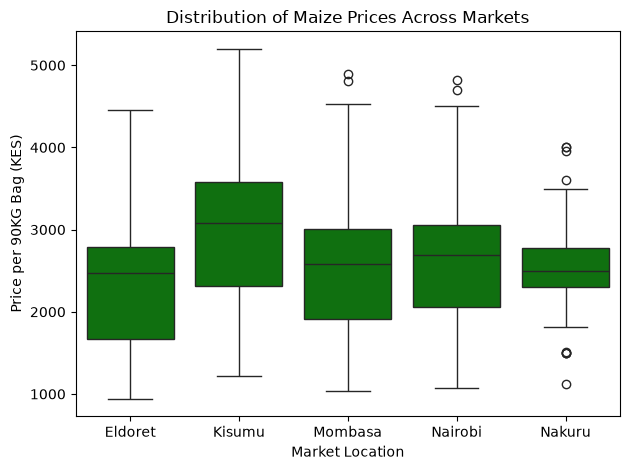

In [146]:
sns.boxplot(data=df_maize, x="market", y="price_kes", color="green")
plt.title("Distribution of Maize Prices Across Markets")
plt.xlabel("Market Location")
plt.ylabel("Price per 90KG Bag (KES)")
plt.tight_layout()

In [147]:
df_maize["price_kes"].describe()

count     721.000000
mean     2568.807351
std       849.836482
min       944.210000
25%      1989.000000
50%      2605.000000
75%      3100.000000
max      5200.000000
Name: price_kes, dtype: float64